# Task 4 - Customer Churn Prediction System

Sqrock IT Solutions - Data Science Internship - Phase 1

Goal: predict whether a customer will churn (leave) or stay.

Pipeline (per the internship brief):
  1. Data Collection      -> IBM Telco Customer Churn dataset (7,043 customers)
  2. Preprocessing        -> missing values, encode categoricals, scaling, train/test split
  3. EDA                  -> churn distribution, charges vs churn, tenure vs churn, heatmap
  4. Feature Engineering  -> average monthly spend, contract grouping, drop CustomerID
  5. Model Building       -> Logistic Regression, Decision Tree, Random Forest, KNN
  6. Evaluation           -> Accuracy, Precision, Recall, F1, Confusion Matrix

Script version: churn_prediction.py

In [1]:
import os
__file__ = os.path.abspath("churn_prediction.py")  # run from the task folder; lets the script's relative paths resolve

In [2]:
from __future__ import annotations

import json
import os
import warnings

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")

HERE = os.path.dirname(os.path.abspath(__file__))
DATA = os.path.join(HERE, "..", "data")
ART = os.path.join(HERE, "artifacts")
WEB = os.path.join(HERE, "..", "web", "assets")
os.makedirs(ART, exist_ok=True); os.makedirs(WEB, exist_ok=True)

PALETTE = {"primary": "#2563eb", "accent": "#f59e0b", "danger": "#ef4444",
           "green": "#10b981", "purple": "#8b5cf6", "slate": "#64748b"}
plt.rcParams.update({"figure.dpi": 130, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.autolayout": True})


def save(fig, name):
    for d in (ART, WEB):
        fig.savefig(os.path.join(d, name), bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"  [chart] {name}")

In [3]:
# Show every chart inline as well as saving it to artifacts/
from IPython.display import Image, display
_save_to_disk = save
def save(fig, name):
    _save_to_disk(fig, name)
    display(Image(os.path.join(ART, name)))

## 1. Collect

In [4]:
print("STEP 1 - Data collection")
df = pd.read_csv(os.path.join(DATA, "telco_churn_ibm.csv"))
print(f"  {df.shape[0]} customers x {df.shape[1]} columns")

STEP 1 - Data collection
  7043 customers x 21 columns


## 2. Preprocess

In [5]:
print("STEP 2 - Data preprocessing")
# TotalCharges is stored as text with blank strings for new customers
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
n_missing = int(df["TotalCharges"].isna().sum())
df["TotalCharges"] = df["TotalCharges"].fillna(df["MonthlyCharges"])
print(f"  coerced TotalCharges, imputed {n_missing} blank value(s)")
df = df.drop_duplicates()

STEP 2 - Data preprocessing
  coerced TotalCharges, imputed 11 blank value(s)


## 4. Feature Engineering

In [6]:
print("STEP 4 - Feature engineering")
df["avg_monthly_spend"] = (df["TotalCharges"] / df["tenure"].replace(0, 1)).round(2)
df["contract_group"] = df["Contract"].map(
    {"Month-to-month": "No commitment", "One year": "Annual", "Two year": "Long-term"})
df["tenure_bucket"] = pd.cut(df["tenure"], [-1, 12, 24, 48, 100],
                             labels=["0-1yr", "1-2yr", "2-4yr", "4yr+"])
df["num_services"] = (df[["PhoneService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                          "TechSupport", "StreamingTV", "StreamingMovies"]]
                      .apply(lambda r: sum(1 for v in r if v == "Yes"), axis=1))
df = df.drop(columns=["customerID"])   # irrelevant identifier (per brief)

df["churn_flag"] = (df["Churn"] == "Yes").astype(int)
print(f"  engineered: avg_monthly_spend, contract_group, tenure_bucket, num_services "
      f"(dropped customerID)")

STEP 4 - Feature engineering


  engineered: avg_monthly_spend, contract_group, tenure_bucket, num_services (dropped customerID)


## 3. Eda

STEP 3 - Exploratory data analysis


  [chart] t4_churn_dist.png


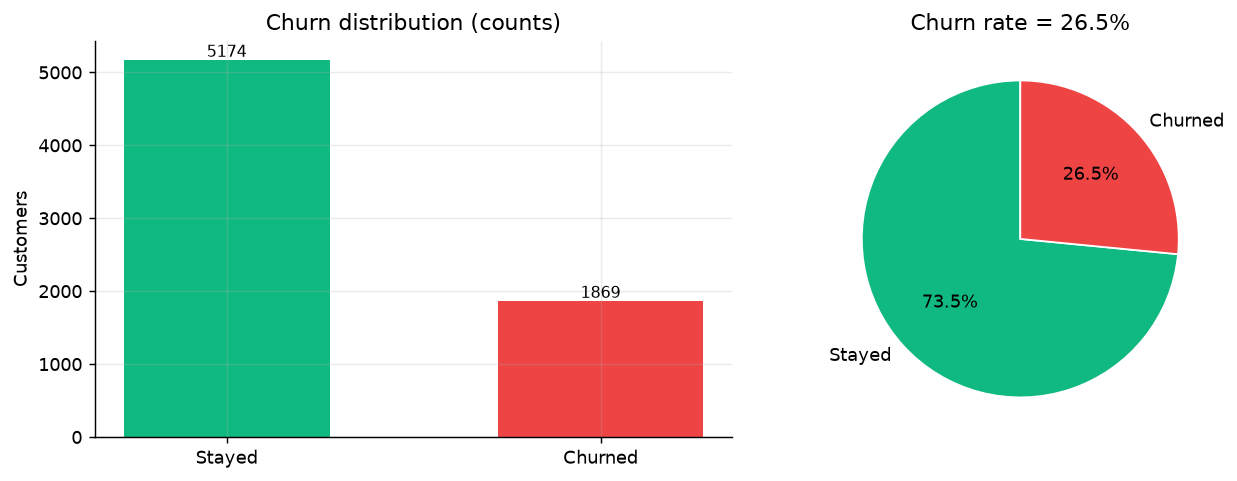

  overall churn rate = 26.5%


  [chart] t4_charges.png


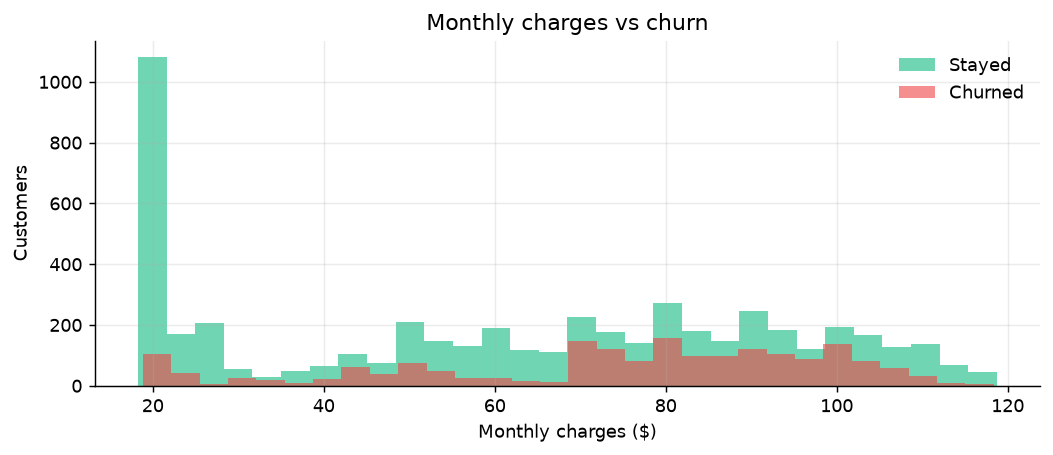

  [chart] t4_tenure.png


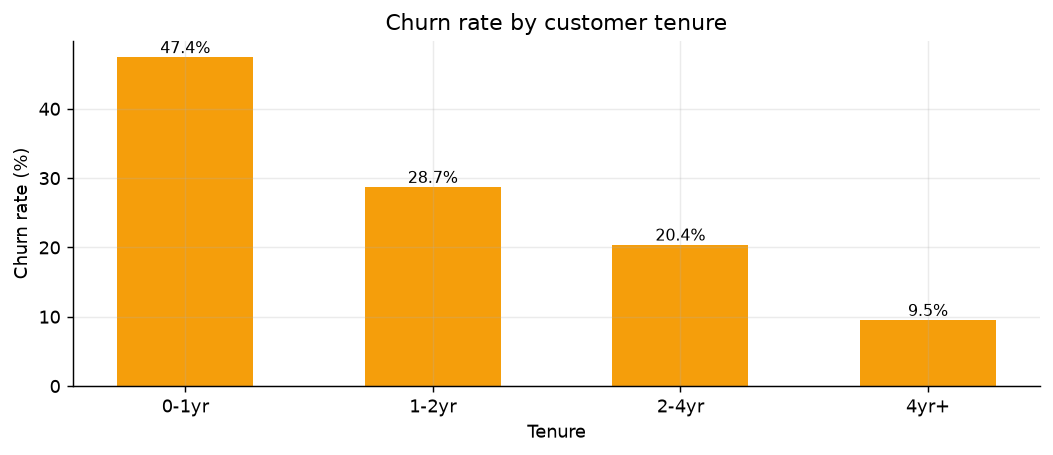

  [chart] t4_corr.png


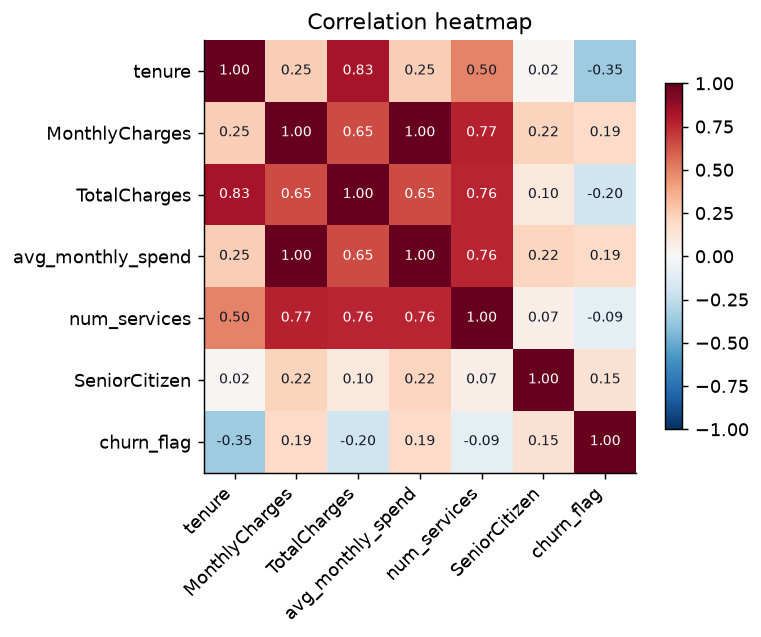

In [7]:
print("STEP 3 - Exploratory data analysis")
counts = df["Churn"].value_counts()
churn_rate = df["churn_flag"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
axes[0].bar(["Stayed", "Churned"], [counts.get("No", 0), counts.get("Yes", 0)],
            color=[PALETTE["green"], PALETTE["danger"]], width=0.55)
axes[0].set_title("Churn distribution (counts)"); axes[0].set_ylabel("Customers")
for i, v in enumerate([counts.get("No", 0), counts.get("Yes", 0)]):
    axes[0].text(i, v + 40, f"{v}", ha="center", fontsize=9)
axes[1].pie([counts.get("No", 0), counts.get("Yes", 0)], labels=["Stayed", "Churned"],
            autopct="%1.1f%%", colors=[PALETTE["green"], PALETTE["danger"]], startangle=90,
            wedgeprops={"edgecolor": "white"})
axes[1].set_title(f"Churn rate = {churn_rate:.1f}%")
save(fig, "t4_churn_dist.png")
print(f"  overall churn rate = {churn_rate:.1f}%")

# monthly charges vs churn
fig, ax = plt.subplots(figsize=(8.2, 3.6))
for label, color in [("No", PALETTE["green"]), ("Yes", PALETTE["danger"])]:
    ax.hist(df[df["Churn"] == label]["MonthlyCharges"], bins=30, alpha=0.6,
            label=f"{'Stayed' if label=='No' else 'Churned'}", color=color)
ax.set_title("Monthly charges vs churn")
ax.set_xlabel("Monthly charges ($)"); ax.set_ylabel("Customers"); ax.legend(frameon=False)
save(fig, "t4_charges.png")

# tenure vs churn
fig, ax = plt.subplots(figsize=(8.2, 3.6))
ten = df.groupby("tenure_bucket", observed=True)["churn_flag"].mean() * 100
ax.bar(ten.index.astype(str), ten.values, color=PALETTE["accent"], width=0.55)
ax.set_title("Churn rate by customer tenure")
ax.set_xlabel("Tenure"); ax.set_ylabel("Churn rate (%)")
for i, v in enumerate(ten.values):
    ax.text(i, v + 0.6, f"{v:.1f}%", ha="center", fontsize=9)
save(fig, "t4_tenure.png")

# correlation heatmap on numeric features
num_cols = ["tenure", "MonthlyCharges", "TotalCharges", "avg_monthly_spend",
            "num_services", "SeniorCitizen", "churn_flag"]
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(6.2, 5.0))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(corr.iloc[i, j]) > 0.55 else "#111827")
ax.set_title("Correlation heatmap"); ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
save(fig, "t4_corr.png")

## 2B. Encode + Split

In [8]:
print("STEP 2b - Encoding, scaling & train/test split")
model_df = df.drop(columns=["Churn", "tenure_bucket"]).copy()
cat_cols = model_df.select_dtypes(include=["object", "category"]).columns.tolist()
for c in cat_cols:
    model_df[c] = model_df[c].astype("category").cat.codes
FEATURES = [c for c in model_df.columns if c != "churn_flag"]
X, y = model_df[FEATURES], model_df["churn_flag"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)
print(f"  encoded {len(cat_cols)} categorical columns | train={len(X_tr)} test={len(X_te)} "
      f"| features={len(FEATURES)}")

STEP 2b - Encoding, scaling & train/test split
  encoded 16 categorical columns | train=5634 test=1409 | features=22


## 5. Models

STEP 5 - Model building
  Logistic Regression  Acc=0.739 P=0.505 R=0.791 F1=0.617 AUC=0.839
  Decision Tree        Acc=0.714 P=0.477 R=0.807 F1=0.600 AUC=0.817


  Random Forest        Acc=0.764 P=0.541 R=0.722 F1=0.619 AUC=0.835
  KNN                  Acc=0.774 P=0.580 R=0.535 F1=0.556 AUC=0.809
  --> best model by F1: Random Forest


  [chart] t4_confusion.png


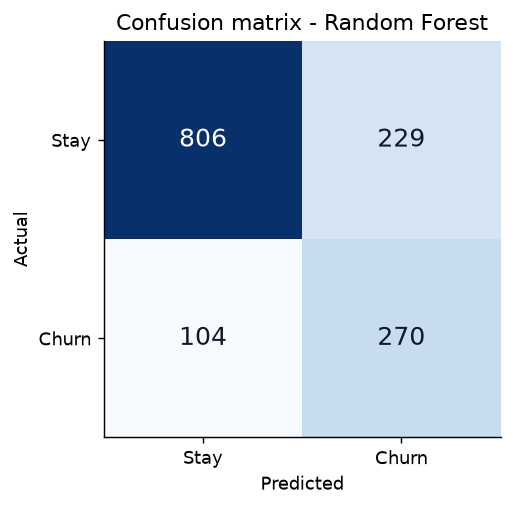

  [chart] t4_model_compare.png


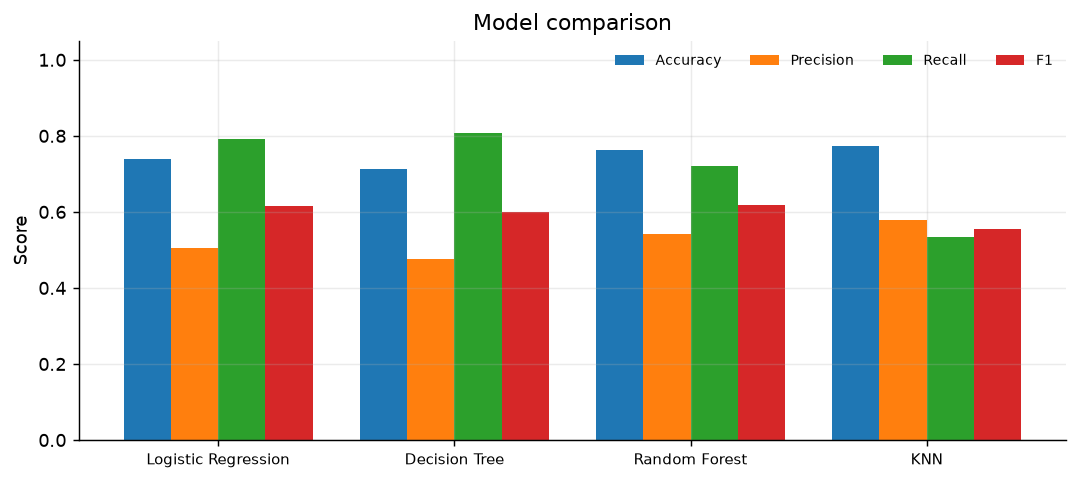

  [chart] t4_roc.png


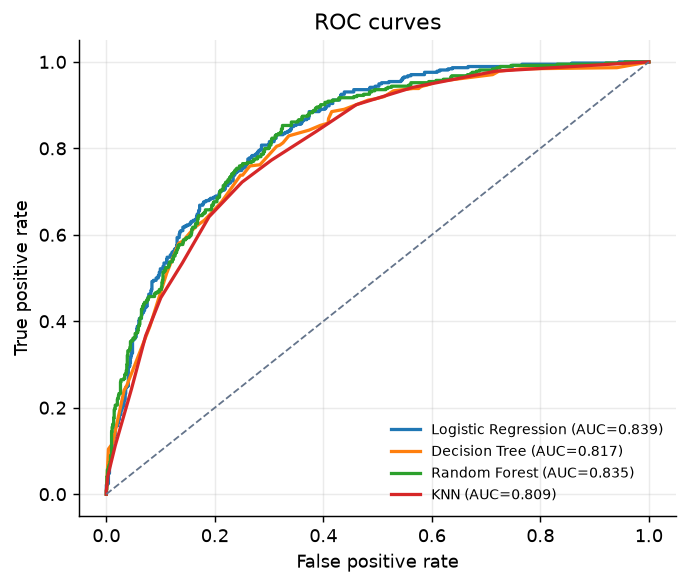

  [chart] t4_importance.png


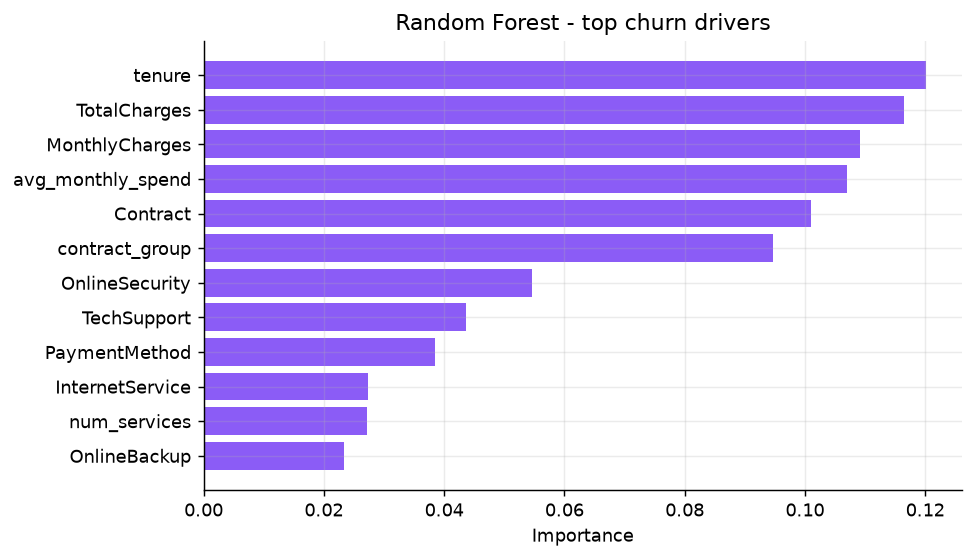

In [9]:
print("STEP 5 - Model building")
models = {
    "Logistic Regression": (LogisticRegression(max_iter=2000, class_weight="balanced"), True),
    "Decision Tree": (DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42), False),
    "Random Forest": (RandomForestClassifier(n_estimators=400, max_depth=12, class_weight="balanced",
                                             random_state=42, n_jobs=-1), False),
    "KNN": (KNeighborsClassifier(n_neighbors=15), True),
}
results, preds, probas = {}, {}, {}
for name, (mdl, needs_scale) in models.items():
    Xtr = X_tr_s if needs_scale else X_tr
    Xte = X_te_s if needs_scale else X_te
    mdl.fit(Xtr, y_tr)
    p = mdl.predict(Xte)
    pr = mdl.predict_proba(Xte)[:, 1]
    preds[name] = p; probas[name] = pr
    results[name] = {
        "Accuracy": round(accuracy_score(y_te, p), 4),
        "Precision": round(precision_score(y_te, p), 4),
        "Recall": round(recall_score(y_te, p), 4),
        "F1": round(f1_score(y_te, p), 4),
        "ROC_AUC": round(roc_auc_score(y_te, pr), 4),
    }
    print(f"  {name:20s} Acc={results[name]['Accuracy']:.3f} "
          f"P={results[name]['Precision']:.3f} R={results[name]['Recall']:.3f} "
          f"F1={results[name]['F1']:.3f} AUC={results[name]['ROC_AUC']:.3f}")

best_model = max(results, key=lambda k: results[k]["F1"])
print(f"  --> best model by F1: {best_model}")

# confusion matrix for the best model
cm = confusion_matrix(y_te, preds[best_model])
fig, ax = plt.subplots(figsize=(4.6, 4.0))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Stay", "Churn"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Stay", "Churn"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                color="white" if cm[i, j] > cm.max() / 2 else "#111827")
ax.set_title(f"Confusion matrix - {best_model}")
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.grid(False)
save(fig, "t4_confusion.png")

# model comparison
fig, ax = plt.subplots(figsize=(8.4, 3.8))
metrics_list = ["Accuracy", "Precision", "Recall", "F1"]
x = np.arange(len(models)); w = 0.2
for i, m in enumerate(metrics_list):
    ax.bar(x + i * w, [results[n][m] for n in models], w, label=m)
ax.set_xticks(x + 1.5 * w); ax.set_xticklabels(list(models.keys()), fontsize=8.5)
ax.set_ylim(0, 1.05); ax.set_ylabel("Score")
ax.set_title("Model comparison"); ax.legend(ncol=4, frameon=False, fontsize=8)
save(fig, "t4_model_compare.png")

# ROC curves
fig, ax = plt.subplots(figsize=(5.4, 4.6))
for name in models:
    fpr, tpr, _ = roc_curve(y_te, probas[name])
    ax.plot(fpr, tpr, lw=1.8, label=f"{name} (AUC={results[name]['ROC_AUC']:.3f})")
ax.plot([0, 1], [0, 1], ls="--", color=PALETTE["slate"], lw=1)
ax.set_title("ROC curves"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.legend(frameon=False, fontsize=8)
save(fig, "t4_roc.png")

# feature importance
rf = models["Random Forest"][0]
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(7.6, 4.4))
ax.barh(imp.index, imp.values, color=PALETTE["purple"])
ax.set_title("Random Forest - top churn drivers")
ax.set_xlabel("Importance")
save(fig, "t4_importance.png")

## 6. Eval + Save

In [10]:
print("STEP 6 - Evaluation & artifacts")
metrics = {
    "task": "Customer Churn Prediction System",
    "dataset": "IBM Telco Customer Churn (7,043 customers, 21 columns)",
    "customers": int(len(df)),
    "churn_rate_pct": round(float(churn_rate), 2),
    "train": int(len(X_tr)), "test": int(len(X_te)),
    "features": FEATURES,
    "engineered_features": ["avg_monthly_spend", "contract_group", "tenure_bucket", "num_services"],
    "models": results, "best_model": best_model,
    "confusion_matrix": {"tn": int(cm[0, 0]), "fp": int(cm[0, 1]),
                         "fn": int(cm[1, 0]), "tp": int(cm[1, 1])},
}
with open(os.path.join(ART, "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2)

# scored test set + at-risk customers (for the web demo)
scored = X_te.copy()
scored["actual"] = y_te.values
scored["churn_probability"] = np.round(probas[best_model], 3)
scored["predicted"] = preds[best_model]
scored.sort_values("churn_probability", ascending=False).head(50).to_csv(
    os.path.join(ART, "at_risk_customers.csv"), index=False)

# export a compact logistic model for the interactive predictor in the web UI.
# NOTE: the models above use class_weight="balanced" (good for recall, but it inflates
# predicted probabilities). For the live calculator we fit an UNWEIGHTED logistic model
# so the probabilities are calibrated against the real ~26% base churn rate.
lr_cal = LogisticRegression(max_iter=2000).fit(X_tr_s, y_tr)
cal_auc = roc_auc_score(y_te, lr_cal.predict_proba(X_te_s)[:, 1])
cal_acc = accuracy_score(y_te, lr_cal.predict(X_te_s))
# baseline vector = median (numeric) / mode (categorical) of the training data
baseline = {}
for c in FEATURES:
    col = X_tr[c]
    baseline[c] = float(col.mode().iloc[0]) if c in cat_cols else float(col.median())
# category -> code maps for the dropdowns exposed in the UI
cat_maps = {}
for col, raw_col in [("Contract", "Contract"), ("InternetService", "InternetService")]:
    cats = sorted(df[raw_col].astype("category").cat.categories.tolist())
    cat_maps[col] = {c: i for i, c in enumerate(cats)}
logit_export = {
    "features": FEATURES,
    "coef": [round(float(c), 4) for c in lr_cal.coef_[0]],
    "intercept": round(float(lr_cal.intercept_[0]), 4),
    "scaler_mean": [round(float(v), 4) for v in scaler.mean_],
    "scaler_scale": [round(float(v), 4) for v in scaler.scale_],
    "baseline": {k: round(v, 4) for k, v in baseline.items()},
    "cat_maps": cat_maps,
    "metrics": {"Accuracy": round(float(cal_acc), 4), "ROC_AUC": round(float(cal_auc), 4)},
    "note": "unweighted logistic regression (calibrated probabilities)",
}
with open(os.path.join(ART, "logit_model.json"), "w") as f:
    json.dump(logit_export, f, indent=2)

web_payload = {
    "metrics": metrics,
    "churn_dist": {"stayed": int(counts.get("No", 0)), "churned": int(counts.get("Yes", 0)),
                   "rate": round(float(churn_rate), 2)},
    "charges": {"stayed": df[df["Churn"] == "No"]["MonthlyCharges"].round(1).tolist(),
                "churned": df[df["Churn"] == "Yes"]["MonthlyCharges"].round(1).tolist()},
    "tenure": {"labels": ten.index.astype(str).tolist(), "values": ten.round(2).tolist()},
    "corr": {"labels": corr.columns.tolist(),
             "values": [[round(float(v), 2) for v in row] for row in corr.values]},
    "confusion": {"matrix": cm.tolist(), "labels": ["Stay", "Churn"], "model": best_model},
    "compare": {"models": list(models.keys()),
                "metrics": {m: [results[n][m] for n in models] for m in metrics_list}},
    "roc": {n: {"fpr": roc_curve(y_te, probas[n])[0].round(4).tolist(),
                "tpr": roc_curve(y_te, probas[n])[1].round(4).tolist(),
                "auc": results[n]["ROC_AUC"]} for n in models},
    "importance": {"labels": imp.index.tolist(), "values": imp.round(4).tolist()},
    "at_risk": scored.sort_values("churn_probability", ascending=False).head(15).round(3)
                     .to_dict(orient="records"),
    "logit_model": logit_export,
}
with open(os.path.join(WEB, "t4_data.json"), "w") as f:
    json.dump(web_payload, f)

print("\n  RESULTS")
for k, v in results.items():
    print(f"    {k:20s} Acc={v['Accuracy']:.3f} P={v['Precision']:.3f} "
          f"R={v['Recall']:.3f} F1={v['F1']:.3f} AUC={v['ROC_AUC']:.3f}")
print(f"  best={best_model} | churn rate={churn_rate:.1f}%")
print("TASK 4 COMPLETE")

STEP 6 - Evaluation & artifacts

  RESULTS
    Logistic Regression  Acc=0.739 P=0.505 R=0.791 F1=0.617 AUC=0.839
    Decision Tree        Acc=0.714 P=0.477 R=0.807 F1=0.600 AUC=0.817
    Random Forest        Acc=0.764 P=0.541 R=0.722 F1=0.619 AUC=0.835
    KNN                  Acc=0.774 P=0.580 R=0.535 F1=0.556 AUC=0.809
  best=Random Forest | churn rate=26.5%
TASK 4 COMPLETE
